# NN_L8_vae_latent

**Lecture 8 of Neural Networks and Deep Learning (NN). Two-dimensional latent means of a variational autoencoder (VAE) for the 10,000 Fashion-MNIST test images, coloured by class (classes were not used in training); k-nearest-neighbour accuracy on the latent means.**

Neural Networks and Deep Learning (NN), Lecture 8 · Daniel Traian Pele, Bucharest University of Economic Studies

[Open in Colab](https://colab.research.google.com/github/danpele/NEURAL_BIZ/blob/main/Quantlets/L8/NN_L8_vae_latent/NN_L8_vae_latent.ipynb)

In [1]:
import os
# course data: the local copy of the repository if there is one, else the public repository on GitHub
_LOCAL = os.path.join('..', '..', '..', 'data', 'clean')
DATA = _LOCAL + os.sep if os.path.isdir(_LOCAL) else 'https://raw.githubusercontent.com/danpele/NEURAL_BIZ/main/data/clean/'
REPO = os.path.join('..', '..', '..') + os.sep if os.path.isdir(_LOCAL) else 'https://raw.githubusercontent.com/danpele/NEURAL_BIZ/main/'

In [2]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
warnings.filterwarnings('ignore')
# course chart style: transparent background, no gridlines, legend at the bottom outside the axes, four-digit years
plt.rcParams.update({
    'figure.facecolor': 'none', 'axes.facecolor': 'none', 'savefig.transparent': True,
    'axes.grid': False, 'axes.spines.top': False, 'axes.spines.right': False,
    'axes.edgecolor': '#222222', 'axes.labelcolor': '#222222', 'xtick.color': '#222222', 'ytick.color': '#222222',
    'text.color': '#222222', 'font.size': 11, 'axes.labelsize': 11, 'legend.fontsize': 10.5, 'legend.frameon': False,
    'lines.linewidth': 1.4, 'font.family': 'DejaVu Sans'})
SERIES = ['#2a78d6', '#eb6834', '#1baf7a', '#eda100', '#e87ba4', '#008300', '#6250d6', '#e34948']
PAL = {'data': '#2a78d6', 'model': '#eb6834', 'benchmark': '#1baf7a', 'alt': '#eda100',
       'train': '#2a78d6', 'valid': '#eb6834', 'test': '#6250d6', 'positive': '#e34948', 'negative': '#2a78d6'}


def legend_bottom(fig, ncol=4):
    h, l_ = [], []
    for ax in fig.axes:
        for hh, ll in zip(*ax.get_legend_handles_labels()):
            if ll not in l_:
                h.append(hh); l_.append(ll)
    if h:
        fig.legend(h, l_, loc='lower center', ncol=min(ncol, len(h)), bbox_to_anchor=(0.5, 0.0), frameon=False)


def show(key, label, value):
    # print a number of the slide; [key] = its name in lectures/Lk/Lk_numbers.json
    print(f'{label} = {value}   [{key}]')

Latent means $\boldsymbol\mu_\phi(\mathbf x)$ of a VAE with $k=2$, 20 epochs, seed 1.

15-NN accuracy on the 2-D latent means (%) = 71.7   [vae.knn_acc_2d]


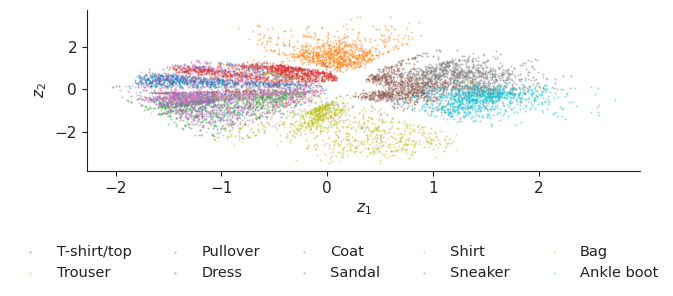

In [3]:
CL = ['T-shirt/top', 'Trouser', 'Pullover', 'Dress', 'Coat', 'Sandal', 'Shirt', 'Sneaker', 'Bag', 'Ankle boot']
z = pd.read_csv(REPO + 'lectures/L8/results/' + 'vae_latent.csv')
from sklearn.neighbors import KNeighborsClassifier
from sklearn.model_selection import cross_val_score
show('vae.knn_acc_2d', '15-NN accuracy on the 2-D latent means (%)', round(100 * float(np.mean(cross_val_score(KNeighborsClassifier(15), z[['z1', 'z2']].values, z.y.values, cv=5))), 1))
fig, ax = plt.subplots(figsize=(6.4, 3.0))
for c in range(10):
    m = z.y == c
    ax.scatter(z.z1[m], z.z2[m], s=2, alpha=0.5, color=plt.cm.tab10(c), lw=0, label=CL[c])
ax.set_xlabel('$z_1$'); ax.set_ylabel('$z_2$')
legend_bottom(fig, ncol=5)
fig.tight_layout(rect=(0, 0.2, 1, 1))
fig.savefig('vae_latent.png', dpi=200, transparent=True, bbox_inches='tight')
plt.show()